In [ ]:
import pandas as pd
df = pd.read_parquet("./results/structural_similarity")

In [ ]:
df["top_k"] = df["top_k"].fillna(-1)
df["Rep_A"] = df["Rep_A"].str.replace(".py","")
df["Rep_A"] = df["Rep_A"].str.replace("run_","")
df["Rep_B"] = df["Rep_B"].str.replace(".py","")
df["Rep_B"] = df["Rep_B"].str.replace("run_","")

In [ ]:
df

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Columns identifying reps
rep_cols = ["Rep_A", "Rep_B"]

# Column identifying score value
value_col = "score"

# Columns defining configuration
config_cols = ["top_k", "normalize"]
print("\n")
for exp_name, df_exp in df.groupby("Experiment"):
    print(f"\nExperiment: {exp_name}")

    for score_name in df_exp["score_name"].unique():
        df_score = df_exp[df_exp["score_name"] == score_name]

        for i, config_values in enumerate(df_score[config_cols].drop_duplicates().to_dict(orient="records")):
            mask = np.ones(len(df_score), dtype=bool)
            for col, val in config_values.items():
                mask &= df_score[col] == val
            subset = df_score[mask]

            if subset.empty:
                continue

            # 1. Pivot table
            heatmap_data = subset.pivot_table(
                index="Rep_A", columns="Rep_B", values=value_col, aggfunc="mean"
            )

            if heatmap_data.empty:
                continue

            # 2. Synchronize index and columns to create a square matrix
            reps = sorted(set(heatmap_data.index) | set(heatmap_data.columns))
            heatmap_data = heatmap_data.reindex(index=reps, columns=reps)

            # 3. SYMMETRIZE: Fill missing (B, A) with existing (A, B) values
            # This makes the matrix order-independent before masking
            heatmap_data = heatmap_data.combine_first(heatmap_data.T)

            # 4. Fill diagonal with 1.0 (identity) if no self-comparison exists
            for r in reps:
                if np.isnan(heatmap_data.loc[r, r]):
                    heatmap_data.loc[r, r] = 1.0

            # 5. Mask the lower triangle for a cleaner "upper triangle only" look
            # k=-1 keeps the diagonal visible
            mask_lower = np.tril(np.ones_like(heatmap_data, dtype=bool), k=-1)

            plt.figure(figsize=(8, 8))
            sns.heatmap(
                heatmap_data,
                annot=True,
                fmt=".3f",
                cmap="viridis",
                mask=mask_lower,
                square=True,
                cbar_kws={"shrink": 0.8}
            )

            config_str = ", ".join(f"{k}={v}" for k, v in config_values.items())
            plt.title(f"{score_name} Heatmap | {config_str}")
            plt.tight_layout()
            plt.show()

In [39]:
# import matplotlib.pyplot as plt
# import matplotlib.cm as cm
# import numpy as np
# import pandas as pd
# from sklearn.manifold import MDS
# from sklearn.preprocessing import StandardScaler, MinMaxScaler

# def dodge_labels_both(x, y, min_offset=0.2):
#     """
#     Dodge labels both up and down to minimize overlap.
#     Returns adjusted y positions and mask of moved labels.
#     """
#     y_dodged = y.copy()
#     moved_mask = np.zeros(len(y), dtype=bool)
#     sorted_idx = np.argsort(y)

#     for i in range(1, len(y)):
#         j = sorted_idx[i]
#         for k in range(i):
#             l = sorted_idx[k]
#             if abs(y_dodged[j] - y_dodged[l]) < min_offset:
#                 shift = min_offset if (i % 2 == 0) else -min_offset
#                 y_dodged[j] += shift
#                 moved_mask[j] = True
#     return y_dodged, moved_mask

# # Fill missing values
# for col in config_cols:
#     df[col] = df[col].fillna(
#         np.inf if pd.api.types.is_numeric_dtype(df[col]) else "__NA__"
#     )

# for score_name, df_score in df.groupby("score_name"):
#     for config_values in df_score[config_cols].drop_duplicates().to_dict(orient="records"):

#         config_values["score_name"] = score_name
#         print("cv", config_values)

#         mask = pd.Series(True, index=df.index)
#         for col, val in config_values.items():
#             mask &= (df[col] == val)

#         df_setting = df[mask]

#         config_str = ", ".join(f"{k}={v}" for k, v in config_values.items()) if config_cols else ""

#         # Collect experiments
#         experiments = list(df_setting.groupby("Experiment"))
#         if len(experiments) == 0:
#             continue

#         fig, axes = plt.subplots(len(experiments), 1, figsize=(8, 5 * len(experiments)), squeeze=False)

#         for row_idx, (experiment_name, df_experiment) in enumerate(experiments):

#             # Build adjacency/similarity matrix
#             nodes = pd.unique(df_experiment[["Rep_A", "Rep_B"]].values.ravel())
#             node_index = {n: i for i, n in enumerate(nodes)}
#             adj_matrix = np.zeros((len(nodes), len(nodes)))

#             for _, row in df_experiment.iterrows():
#                 i = node_index[row["Rep_A"]]
#                 j = node_index[row["Rep_B"]]
#                 adj_matrix[i, j] = adj_matrix[j, i] = row["score"]

#             # Standardize adjacency
#             adj_scaled = StandardScaler().fit_transform(adj_matrix)

#             # Convert similarity → distance
#             distance_matrix = 1 - adj_scaled
#             distance_matrix = (distance_matrix + distance_matrix.T) / 2
#             np.fill_diagonal(distance_matrix, 0)

#             # MDS embedding
#             # MDS embedding
#             mds = MDS(
#                 n_components=2,
#                 dissimilarity='precomputed',
#                 random_state=42,
#                 n_init=10,
#                 max_iter=3000
#             )
#             pos_mds = mds.fit_transform(distance_matrix)

#             # Optionally scale if needed
#             pos_mds_scaled = MinMaxScaler().fit_transform(pos_mds)

#             # Shift so "model_embd" is at (0,0)
#             if "model_embd" in node_index:
#                 center_idx = node_index["model_embd"]
#                 shift = -pos_mds_scaled[center_idx]  # move this point to 0,0
#                 pos_mds_scaled += shift

#             # Label dodge
#             y_dodged, moved_mask = dodge_labels_both(pos_mds_scaled[:, 0], pos_mds_scaled[:, 1], min_offset=0.05)

#             # Assign colors
#             cmap = cm.get_cmap('tab20', len(nodes))
#             node_colors = {node: cmap(i) for i, node in enumerate(nodes)}

#             # Plot
#             ax = axes[row_idx, 0]
#             ax.scatter(pos_mds_scaled[:, 0], pos_mds_scaled[:, 1], s=100, c=[node_colors[node] for node in nodes])

#             for i, node in enumerate(nodes):
#                 x_text = pos_mds_scaled[i, 0] + 0.02
#                 y_text = y_dodged[i]

#                 if moved_mask[i]:
#                     ax.annotate(
#                         node,
#                         xy=(pos_mds_scaled[i, 0], pos_mds_scaled[i, 1]),
#                         xytext=(x_text, y_text),
#                         arrowprops=dict(
#                             arrowstyle="->",
#                             lw=0.8,
#                             connectionstyle="arc3,rad=0.2",
#                             color=node_colors[node]
#                         ),
#                         fontsize=9,
#                         ha='left',
#                         va='center',
#                         color=node_colors[node],
#                     )
#                 else:
#                     ax.text(x_text, y_text, node, fontsize=9, ha='left', va='center', color=node_colors[node])

#             ax.set_title(f"MDS — {experiment_name}")
#             ax.set_xlabel("Dim 1")
#             ax.set_ylabel("Dim 2")
#             ax.set_xlim(-1,1)
#             ax.set_ylim(-1,1)

#         fig.suptitle(f"{score_name} | {config_str}", fontsize=14)
#         plt.tight_layout()
#         plt.show()

cv {'top_k': -1, 'normalize': False, 'score_name': 'cka'}
cv {'top_k': -1, 'normalize': True, 'score_name': 'cka'}


/tmp/ipykernel_2766422/2703128450.py:112: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20', len(nodes))
/tmp/ipykernel_2766422/2703128450.py:112: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20', len(nodes))


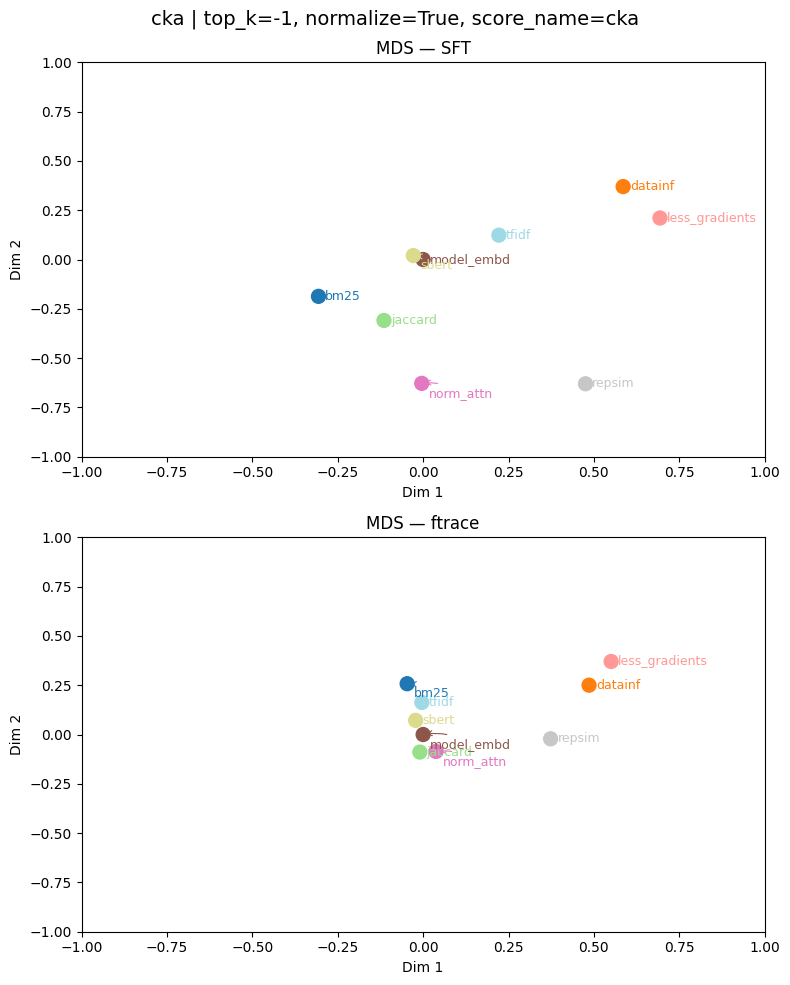

cv {'top_k': 10, 'normalize': False, 'score_name': 'cknna'}
cv {'top_k': 10, 'normalize': True, 'score_name': 'cknna'}


/tmp/ipykernel_2766422/2703128450.py:112: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20', len(nodes))
/tmp/ipykernel_2766422/2703128450.py:112: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20', len(nodes))


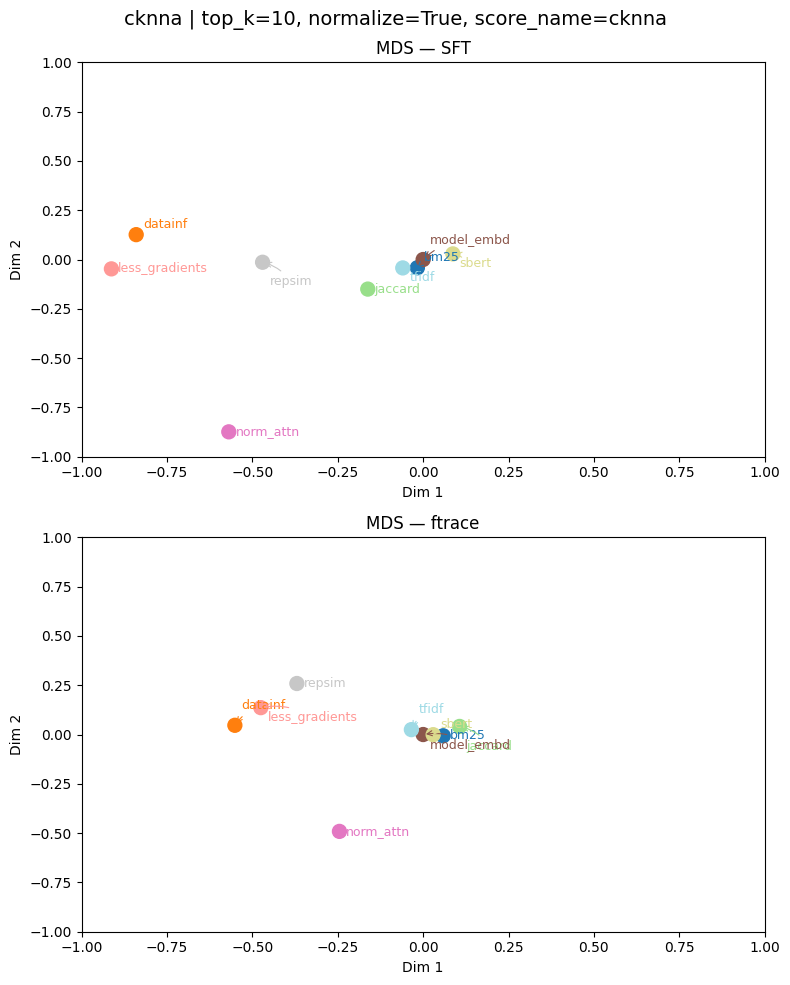

cv {'top_k': 20, 'normalize': False, 'score_name': 'cknna'}
cv {'top_k': 20, 'normalize': True, 'score_name': 'cknna'}


/tmp/ipykernel_2766422/2703128450.py:112: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20', len(nodes))
/tmp/ipykernel_2766422/2703128450.py:112: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20', len(nodes))


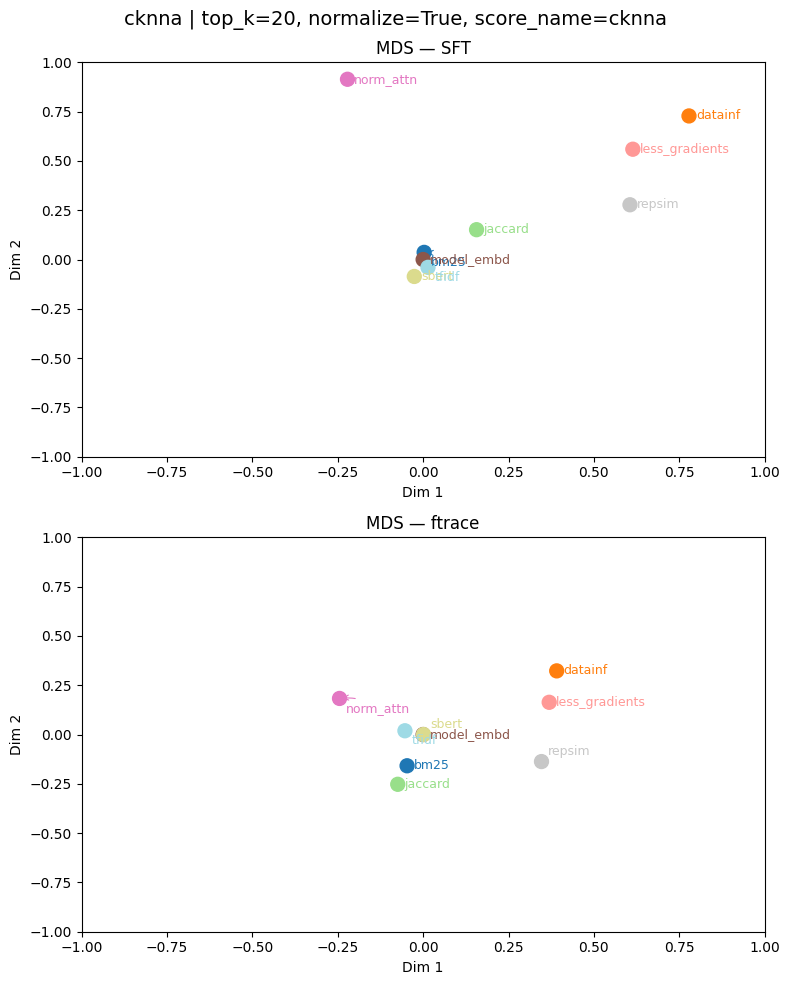

cv {'top_k': 10, 'normalize': False, 'score_name': 'cycle_knn'}
cv {'top_k': 10, 'normalize': True, 'score_name': 'cycle_knn'}
cv {'top_k': 20, 'normalize': False, 'score_name': 'cycle_knn'}
cv {'top_k': 20, 'normalize': True, 'score_name': 'cycle_knn'}


In [45]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import pandas as pd
from sklearn.manifold import MDS
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from scipy.spatial import procrustes

def dodge_labels_both(x, y, min_offset=0.2):
    """
    Dodge labels both up and down to minimize overlap.
    Returns adjusted y positions and mask of moved labels.
    """
    y_dodged = y.copy()
    moved_mask = np.zeros(len(y), dtype=bool)
    sorted_idx = np.argsort(y)

    for i in range(1, len(y)):
        j = sorted_idx[i]
        for k in range(i):
            l = sorted_idx[k]
            if abs(y_dodged[j] - y_dodged[l]) < min_offset:
                shift = min_offset if (i % 2 == 0) else -min_offset
                y_dodged[j] += shift
                moved_mask[j] = True
    return y_dodged, moved_mask

# Fill missing values
for col in config_cols:
    df[col] = df[col].fillna(
        np.inf if pd.api.types.is_numeric_dtype(df[col]) else "__NA__"
    )

for score_name, df_score in df.groupby("score_name"):
    for config_values in df_score[config_cols].drop_duplicates().to_dict(orient="records"):

        config_values["score_name"] = score_name
        print("cv", config_values)
        if not config_values["normalize"] or "cycle" in config_values["score_name"]:
            continue

        mask = pd.Series(True, index=df.index)
        for col, val in config_values.items():
            mask &= (df[col] == val)

        df_setting = df[mask]

        config_str = ", ".join(f"{k}={v}" for k, v in config_values.items()) if config_cols else ""

        # Collect experiments
        experiments = list(df_setting.groupby("Experiment"))
        if len(experiments) == 0:
            continue

        # Prepare figure
        fig, axes = plt.subplots(len(experiments), 1, figsize=(8, 5 * len(experiments)), squeeze=False)

        # Will store reference embedding for Procrustes
        ref_pos = None

        for row_idx, (experiment_name, df_experiment) in enumerate(experiments):

            # Build adjacency/similarity matrix
            nodes = pd.unique(df_experiment[["Rep_A", "Rep_B"]].values.ravel())
            node_index = {n: i for i, n in enumerate(nodes)}
            adj_matrix = np.zeros((len(nodes), len(nodes)))

            for _, row in df_experiment.iterrows():
                i = node_index[row["Rep_A"]]
                j = node_index[row["Rep_B"]]
                adj_matrix[i, j] = adj_matrix[j, i] = row["score"]

            # Standardize adjacency
            adj_scaled = StandardScaler().fit_transform(adj_matrix)

            # Convert similarity → distance
            distance_matrix = 1 - adj_scaled
            distance_matrix = (distance_matrix + distance_matrix.T) / 2
            np.fill_diagonal(distance_matrix, 0)

            # MDS embedding
            mds = MDS(
                n_components=2,
                dissimilarity='precomputed',
                random_state=42,
                n_init=10,
                max_iter=3000
            )
            pos_mds = mds.fit_transform(distance_matrix)

            # Scale to [0,1]
            pos_mds_scaled = MinMaxScaler().fit_transform(pos_mds)

            # Shift so "model_embd" is at (0,0)
            if "model_embd" in node_index:
                center_idx = node_index["model_embd"]
                pos_mds_scaled -= pos_mds_scaled[center_idx]

            # Align to reference using Procrustes
            if ref_pos is None:
                ref_pos = pos_mds_scaled.copy()  # first experiment is reference
            else:
                _, pos_mds_scaled, _ = procrustes(ref_pos, pos_mds_scaled)
                # After Procrustes, re-center "model_embd" exactly at (0,0)
                center_idx = node_index["model_embd"]
                pos_mds_scaled -= pos_mds_scaled[center_idx]

            # Label dodge
            y_dodged, moved_mask = dodge_labels_both(pos_mds_scaled[:, 0], pos_mds_scaled[:, 1], min_offset=0.05)

            # Assign colors
            cmap = cm.get_cmap('tab20', len(nodes))
            node_colors = {node: cmap(i) for i, node in enumerate(nodes)}

            # Plot
            ax = axes[row_idx, 0]
            ax.scatter(pos_mds_scaled[:, 0], pos_mds_scaled[:, 1], s=100, c=[node_colors[node] for node in nodes])

            for i, node in enumerate(nodes):
                x_text = pos_mds_scaled[i, 0] + 0.02
                y_text = y_dodged[i]

                if moved_mask[i]:
                    ax.annotate(
                        node,
                        xy=(pos_mds_scaled[i, 0], pos_mds_scaled[i, 1]),
                        xytext=(x_text, y_text),
                        arrowprops=dict(
                            arrowstyle="->",
                            lw=0.8,
                            connectionstyle="arc3,rad=0.2",
                            color=node_colors[node]
                        ),
                        fontsize=9,
                        ha='left',
                        va='center',
                        color=node_colors[node],
                    )
                else:
                    ax.text(x_text, y_text, node, fontsize=9, ha='left', va='center', color=node_colors[node])

            # Set title and labels
            ax.set_title(f"MDS — {experiment_name}")
            ax.set_xlabel("Dim 1")
            ax.set_ylabel("Dim 2")

            # Dynamic axes limits with padding
            x_min, x_max = pos_mds_scaled[:, 0].min(), pos_mds_scaled[:, 0].max()
            y_min, y_max = pos_mds_scaled[:, 1].min(), pos_mds_scaled[:, 1].max()
            padding_x = 0.05 * (x_max - x_min)
            padding_y = 0.05 * (y_max - y_min)
            ax.set_xlim(-1,1)
            ax.set_ylim(-1,1)

        fig.suptitle(f"{score_name} | {config_str}", fontsize=14)
        plt.tight_layout()
        plt.show()

In [ ]:
# !python3 -m structural_similarity --model ./models/Llama-3.2-1B_tulu-3-sft-olmo-2-mixture-0225_lr0.0001_seed42 --train_dataset_name loris3/tulu-3-sft-olmo-2-mixture-0225-sample --train_dataset_split train --test_dataset_name loris3/tulu-3-sft-olmo-2-mixture-0225-sample --test_dataset_split test --top_k 10 20 --sim_script_a representations/run_bm25.py --sim_script_b representations/run_datainf.py --experiment_name SFT

In [ ]:
pd.read_parquet("/mnt/nlp-data/home/users/loriss21cs/eemc/results/structural_similarity/SFT/loris3/tulu-3-sft-olmo-2-mixture-0225-sample/train/loris3/tulu-3-sft-olmo-2-mixture-0225-sample/test/models/Llama-3.2-1B_tulu-3-sft-olmo-2-mixture-0225_lr0.0001_seed42/run_bm25_run_datainf/")

In [ ]:
# import networkx as nx
# import matplotlib.pyplot as plt

# for name, features in results.items():
#     print(name)
#     G = nx.Graph()

#     # Add nodes
#     for node_name in heatmap_data.index:
#         G.add_node(node_name)

#     # Add edges above threshold
#     threshold = 0.7
#     for i, name1 in enumerate(heatmap_data.index):
#         for j, name2 in enumerate(heatmap_data.columns):
#             if i < j and heatmap_data.loc[name1, name2] > threshold:
#                 G.add_edge(name1, name2, weight=heatmap_data.loc[name1, name2])

#     # Layout
#     pos = nx.spring_layout(G, seed=42)
#     edges = G.edges()
#     weights = [G[u][v]['weight']*2 for u, v in edges]  # scale weights

#     # Draw nodes and edges
#     nx.draw(G, pos, with_labels=False, width=weights, node_size=100, node_color="skyblue")

#     # Draw labels with small random offset (dodge)
#     for node, (x, y) in pos.items():
#         offset_x = 0.02  # tweak as needed
#         offset_y = 0.02
#         plt.text(x + offset_x, y + offset_y, node, fontsize=10)

#     plt.show()

In [ ]:
# import torch
# torch.count_nonzero( results["SFT"]["Jaccard_Llama-3.2-1B_tulu-3"])
# (results["ftrace"]["BM25_OLMo-2"][19] == results["ftrace"]["BM25_OLMo-2"][2]).sum()